 Team Members: Brandon, Christina and Isaac

AGENTIC MARKET RESEARCH SYSTEM
Local model: llama3.2:latest
NewsAPI: API key detected (value hidden)
Yahoo Finance: enabled
Google News RSS fallback: enabled

Market research agent created successfully.



Enter stock ticker in CAPS (e.g., AAPL, MSFT, NVDA):  NVDA



🔎 Checking ticker: NVDA
✅ Found NVDA.

MARKET / FINANCIAL RESEARCH

AGENTIC MARKET RESEARCH: NVDA

🧠 STEP 1 — PLAN
{
  "objectives": [],
  "tools": [
    "price_data",
    "company_info",
    "financials",
    "cash_flow",
    "sec_edgar"
  ],
  "questions": [
    {
      "question": "What is NVIDIA's latest stock price?",
      "tool": "price_data"
    },
    {
      "question": "What is NVIDIA's one-year return percentage?",
      "tool": "financials"
    },
    {
      "question": "What is NVIDIA's capital expenditure for the latest fiscal year?",
      "tool": "financials"
    },
    {
      "question": "Why is NVIDIA's capital expenditure reported as -$604,200,000?",
      "tool": "financials",
      "specific_data": "capital_expenditure"
    },
    {
      "question": "What are the factors driving NVIDIA Corporation's revenue growth?",
      "tool": "financials",
      "specific_data": "revenue_growth"
    },
    {
      "question": "How does NVIDIA Corporation's cash flow gener

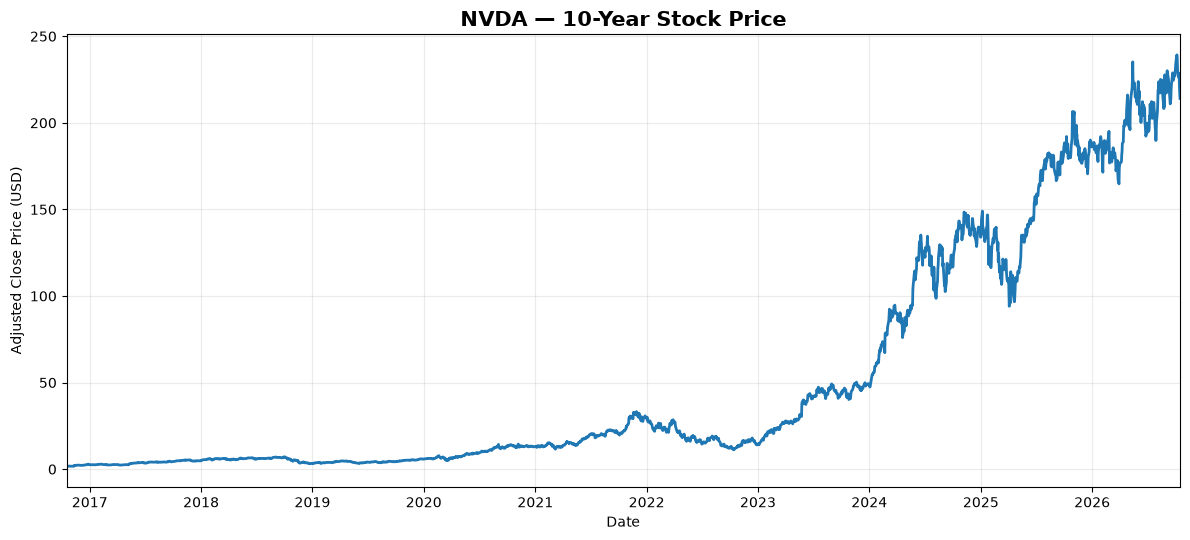

10-year price summary: $1.61 → $214.13 (+13,203.3%)

5-YEAR REVENUE ANALYSIS


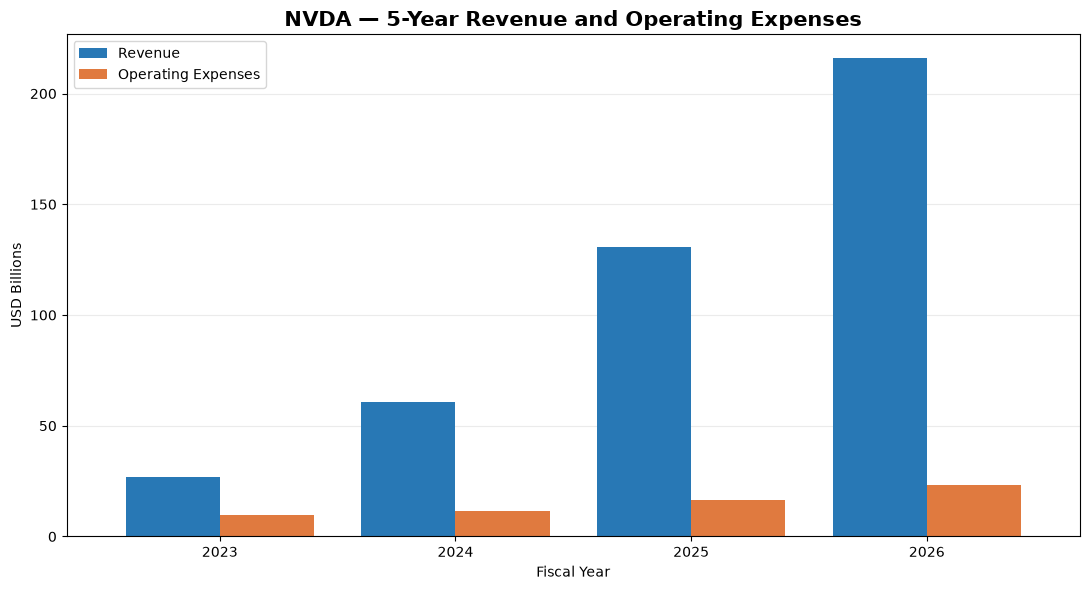


5-Year Financial Summary — NVDA
-------------------------------------------------------
2023: Revenue $26.97B | Operating Expenses $9.78B
2024: Revenue $60.92B | Operating Expenses $11.33B
2025: Revenue $130.50B | Operating Expenses $16.41B
2026: Revenue $215.94B | Operating Expenses $23.08B

LLM RESEARCH REPORT
# NVDA Market Research

## 1. Company Overview

NVIDIA Corporation is a leading technology company that specializes in designing and manufacturing graphics processing units (GPUs) and high-performance computing hardware.

## 2. Price Performance

### Current Price
The current price of NVIDIA Corporation is $214.13.

### 1-Year Return Percentage
The 1-year return percentage of NVIDIA Corporation is 17.15%.

### Annualized Volatility Percentage
The annualized volatility percentage of NVIDIA Corporation is 37.4%.

### Maximum Drawdown Percentage
The maximum drawdown percentage of NVIDIA Corporation is -20.21%.

### Observations
The price data is available for 251 observations ove

In [2]:
#
print("\033[1m Team Members: Brandon, Christina and Isaac\033[0m")
print()
#

# Agent Functions:

#1.	Plans its research steps for a given stock symbol.
#2.	Uses tools dynamically (APIs, datasets, retrieval).
#3.	Self-reflects to assess the quality of its output.
#4.	Learns across runs (e.g., keeps brief memories or notes to improve future analyses).

# Workflow Patterns:

#1.	Prompt Chaining: Ingest News → Preprocess → Classify → Extract → Summarize
#2.	Routing: Direct content to the right specialist (e.g., earnings, news, or market analyzers).
#3.	Evaluator–Optimizer: Generate analysis → evaluate quality → refine using feedback.

# Code:

# Sources:
#   1. Yahoo Finance
#   2. SEC EDGAR
#   3. NewsAPI.org
#   4. Yahoo Finance News
#   5. Google News 

# Features:
#   - Stock ticker input and validation
#   - Market data retrieval via Yahoo Finance
#   - Company profile and information retrieval
#   - Financial statement analysis
#   - Cash flow analysis
#   - SEC EDGAR company facts and filings
#   - Recent SEC filing analysis
#   - News collection and sentiment analysis
#   - LLM-based research planning
#   - Cross-source data validation
#   - Self-reflection and quality checks
#   - Persistent memory and historical context
#   - 10-year stock price and performance analysis
#
# ======================================================================


# ======================================================================
# AGENTIC MARKET RESEARCH + NEWS ANALYSIS SYSTEM
# ======================================================================
#
# Architecture:

# MARKET RESEARCH:
#   Planner
#      ↓
#   Tools
#      ↓
#   Validation
#      ↓
#   Reflection
#      ↓
#   Report
#      ↓
#   Memory


# NEWS RESEARCH:
#   Ingest
#      ↓
#   Preprocess
#      ↓
#   Classify
#      ↓
#   Extract
#      ↓
#   Summarize
#      ↓
#   Route
#      ↓
#   Specialist
#      ↓
#   Evaluator
#      ↓
#   Optimizer

# NEWS SOURCES
#   1. Yahoo Finance
#   2. NewsAPI
#   3. Google News RSS fallback
#
# ======================================================================


# ======================================================================
# INSTALLATION
# ======================================================================

# Install yfinance matplotlib as needed
#%pip install -q "pandas<3" ollama yfinance matplotlib requests


# ======================================================================
# IMPORTS
# ======================================================================



import json
import os
import re
import time
import ssl
import html
from pathlib import Path
from datetime import datetime
from numbers import Number
from urllib.parse import urlparse, quote_plus
from email.utils import parsedate_to_datetime

import ollama
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import requests

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


# ======================================================================
# CONFIGURATION
# ======================================================================

MODEL = "llama3.2:latest"

MEMORY_FILE = Path(
    "market_agent_memory.json"
)


# ======================================================================
# NEWSAPI CONFIGURATION
# ======================================================================

import os

# ----------------------------------------------------------------------
# NEWSAPI
# ----------------------------------------------------------------------

# Directly configured NewsAPI key
# Replace the value below with your active NewsAPI key.
NEWSAPI_KEY = "fb45798c4eae4764a1f74bf45b363e99"

NEWSAPI_BASE_URL = "https://newsapi.org/v2"

NEWSAPI_EVERYTHING_URL = (
    f"{NEWSAPI_BASE_URL}/everything"
)

NEWSAPI_NEWS_COUNT = 8
YAHOO_NEWS_COUNT = 8
RSS_NEWS_COUNT = 8
MAX_NEWS_ARTICLES = 16


# ======================================================================
# SEC CONFIGURATION
# ======================================================================

SEC_USER_AGENT = os.getenv(
    "SEC_USER_AGENT",
    "AcademicMarketResearch/1.0 contact@example.com",
)

SEC_BASE_URL = (
    "https://data.sec.gov"
)

SEC_TICKER_URL = (
    "https://www.sec.gov/files/company_tickers.json"
)


# ======================================================================
# HTTP CONFIGURATION
# ======================================================================

HTTP_TIMEOUT = (
    15,
    45,
)

HTTP_RETRIES = 3

USER_AGENT = (
    "Mozilla/5.0 "
    "(Windows NT 10.0; Win64; x64) "
    "AppleWebKit/537.36 "
    "(KHTML, like Gecko) "
    "Chrome/131.0 Safari/537.36"
)


# ======================================================================
# STARTUP CHECK
# ======================================================================

print("=" * 78)
print("AGENTIC MARKET RESEARCH SYSTEM")
print("=" * 78)

print(
    f"Local model: {MODEL}"
)

if NEWSAPI_KEY:

    print(
        "NewsAPI: API key detected "
        "(value hidden)"
    )

else:

    print(
        "NewsAPI: API key not configured"
    )

    print(
        "NewsAPI will be skipped and "
        "fallback news sources will be used."
    )

print(
    "Yahoo Finance: enabled"
)

print(
    "Google News RSS fallback: enabled"
)

print("=" * 78)


# ======================================================================
# HTTP SESSION
# ======================================================================

def create_http_session():

    session = requests.Session()

    retry = Retry(

        total=HTTP_RETRIES,

        connect=HTTP_RETRIES,

        read=HTTP_RETRIES,

        status=HTTP_RETRIES,

        backoff_factor=1.0,

        status_forcelist=[
            429,
            500,
            502,
            503,
            504,
        ],

        allowed_methods=[
            "GET",
        ],

        raise_on_status=False,
    )

    adapter = HTTPAdapter(
        max_retries=retry,
        pool_connections=10,
        pool_maxsize=10,
    )

    session.mount(
        "https://",
        adapter,
    )

    session.mount(
        "http://",
        adapter,
    )

    session.headers.update({

        "User-Agent":
            USER_AGENT,

        "Accept":
            "application/json,text/html,"
            "application/xhtml+xml,"
            "application/xml;q=0.9,*/*;q=0.8",

    })

    return session


HTTP_SESSION = create_http_session()


# ======================================================================
# LLM HELPER
# ======================================================================

def ask_llm(prompt):

    response = ollama.chat(

        model=MODEL,

        messages=[

            {
                "role": "user",
                "content": prompt,
            }

        ],
    )

    return response[
        "message"
    ][
        "content"
    ]


# ======================================================================
# GENERIC HELPERS
# ======================================================================

def safe_float(value):

    if value is None:
        return None

    try:

        return float(value)

    except (
        TypeError,
        ValueError,
    ):

        return None


def normalize_text(text):

    if not text:
        return ""

    return re.sub(
        r"\s+",
        " ",
        str(text),
    ).strip()


def normalize_title(title):

    if not title:
        return ""

    title = str(title).lower()

    title = re.sub(
        r"[^a-z0-9\s]",
        "",
        title,
    )

    title = re.sub(
        r"\s+",
        " ",
        title,
    ).strip()

    return title


def normalize_article_url(url):

    if not url or url == "N/A":
        return ""

    try:

        parsed = urlparse(
            str(url)
        )

        normalized = (
            f"{parsed.scheme}://"
            f"{parsed.netloc}"
            f"{parsed.path}"
        )

        return (
            normalized
            .lower()
            .rstrip("/")
        )

    except Exception:

        return (
            str(url)
            .lower()
            .strip()
        )


def clean_html(text):

    if not text:
        return ""

    text = html.unescape(
        str(text)
    )

    text = re.sub(
        r"<[^>]+>",
        " ",
        text,
    )

    return normalize_text(
        text
    )


def parse_date_to_iso(value):

    if not value:
        return None

    value = str(value)

    try:

        dt = parsedate_to_datetime(
            value
        )

        return dt.isoformat()

    except Exception:
        pass

    try:

        dt = pd.to_datetime(
            value,
            utc=True,
        )

        return dt.isoformat()

    except Exception:
        return value


def deduplicate_list(values):

    result = []

    seen = set()

    for value in values:

        key = str(value).strip().lower()

        if (
            key
            and key not in seen
        ):

            seen.add(key)

            result.append(
                value
            )

    return result


# ======================================================================
# TICKER → COMPANY NAME
# ======================================================================

KNOWN_COMPANIES = {

    "AAPL":
        "Apple",

    "MSFT":
        "Microsoft",

    "NVDA":
        "NVIDIA",

    "AMZN":
        "Amazon",

    "GOOGL":
        "Alphabet",

    "GOOG":
        "Alphabet",

    "META":
        "Meta",

    "TSLA":
        "Tesla",

    "AVGO":
        "Broadcom",

    "AMD":
        "AMD",

    "NFLX":
        "Netflix",

    "ORCL":
        "Oracle",

    "CRM":
        "Salesforce",

    "INTC":
        "Intel",

    "QCOM":
        "Qualcomm",

    "JPM":
        "JPMorgan",

    "V":
        "Visa",

    "MA":
        "Mastercard",

    "WMT":
        "Walmart",

    "COST":
        "Costco",

}


def get_company_name(
    ticker_symbol
):

    ticker_symbol = (
        ticker_symbol
        .upper()
        .strip()
    )

    if ticker_symbol in KNOWN_COMPANIES:

        return KNOWN_COMPANIES[
            ticker_symbol
        ]

    try:

        info = yf.Ticker(
            ticker_symbol
        ).info

        name = info.get(
            "longName"
        ) or info.get(
            "shortName"
        )

        if name:
            return name

    except Exception:
        pass

    return ticker_symbol


# ======================================================================
# YAHOO FINANCE — PRICE DATA
# ======================================================================

def get_price_data(
    symbol,
    period="1y",
):

    ticker = yf.Ticker(
        symbol
    )

    df = ticker.history(
        period=period
    )

    if df.empty:

        return {
            "error":
                f"No price data found for {symbol}"
        }

    close = (
        df["Close"]
        .dropna()
    )

    if close.empty:

        return {
            "error":
                f"No closing-price data found for {symbol}"
        }

    start_price = float(
        close.iloc[0]
    )

    latest_price = float(
        close.iloc[-1]
    )

    total_return = (
        latest_price
        / start_price
        - 1
    ) * 100

    daily_returns = (
        close
        .pct_change()
        .dropna()
    )

    volatility = (
        daily_returns.std()
        * (252 ** 0.5)
    ) * 100

    running_max = (
        close.cummax()
    )

    drawdown = (
        close
        / running_max
        - 1
    ) * 100

    return {

        "start_price":
            round(
                start_price,
                2,
            ),

        "latest_price":
            round(
                latest_price,
                2,
            ),

        "1y_return_percent":
            round(
                total_return,
                2,
            ),

        "annualized_volatility_percent":
            round(
                float(volatility),
                2,
            ),

        "maximum_drawdown_percent":
            round(
                float(drawdown.min()),
                2,
            ),

        "observations":
            len(df),

        "period":
            period,

    }


# ======================================================================
# YAHOO FINANCE — COMPANY INFORMATION
# ======================================================================

def get_company_info(symbol):

    ticker = yf.Ticker(
        symbol
    )

    try:

        info = ticker.info

    except Exception as exc:

        return {
            "error":
                f"{type(exc).__name__}: {exc}"
        }

    fields = [

        "longName",
        "shortName",
        "sector",
        "industry",
        "country",
        "marketCap",
        "enterpriseValue",
        "currentPrice",
        "regularMarketPrice",
        "trailingPE",
        "forwardPE",
        "priceToSalesTrailing12Months",
        "profitMargins",
        "operatingMargins",
        "returnOnEquity",
        "beta",
        "dividendYield",

    ]

    result = {

        field:
            info.get(field)

        for field in fields

    }

    return result


# ======================================================================
# FINANCIAL STATEMENTS
# ======================================================================

def dataframe_to_serializable(
    dataframe,
    rows,
    max_columns=4,
):

    if dataframe is None:
        return {}

    if dataframe.empty:
        return {}

    result = {}

    for row in rows:

        if row not in dataframe.index:
            continue

        values = (
            dataframe
            .loc[row]
            .iloc[:max_columns]
        )

        result[row] = {

            str(date): (

                None

                if pd.isna(value)

                else float(value)

            )

            for date, value
            in values.items()

        }

    return result


def get_financials(symbol):

    ticker = yf.Ticker(
        symbol
    )

    try:

        income = ticker.income_stmt

    except Exception as exc:

        return {
            "error":
                f"{type(exc).__name__}: {exc}"
        }

    if income.empty:

        return {
            "error":
                "No financial statements found"
        }

    wanted = [

        "Total Revenue",
        "Operating Expenses",
        "Operating Income",
        "Net Income",
        "EBITDA",
        "Diluted EPS",

    ]

    result = (
        dataframe_to_serializable(
            income,
            wanted,
            4,
        )
    )

    # Fill Operating Expenses if Yahoo Finance omits the direct row.
    expenses = _operating_expenses_series(income)
    if not expenses.empty:
        result["Operating Expenses"] = {
            str(date): (None if pd.isna(value) else float(value))
            for date, value in expenses.iloc[:4].items()
        }

    return {

        "statement":
            "income_statement",

        "data":
            result,

        "note":
            "Yahoo Finance income-statement "
            "periods are labeled by their "
            "is a quarter. Operating Expenses may "
            "reported financial period; "
            "do not assume the first column "
            "is a quarter.",

    }


# ======================================================================
# CASH FLOW
# ======================================================================

def get_cash_flow(symbol):

    ticker = yf.Ticker(
        symbol
    )

    try:

        cashflow = ticker.cashflow

    except Exception as exc:

        return {
            "error":
                f"{type(exc).__name__}: {exc}"
        }

    if cashflow.empty:

        return {
            "error":
                "No cash-flow data found"
        }

    wanted = [

        "Operating Cash Flow",
        "Free Cash Flow",
        "Capital Expenditure",

    ]

    result = (
        dataframe_to_serializable(
            cashflow,
            wanted,
            4,
        )
    )

    return {

        "statement":
            "cash_flow",

        "data":
            result,

    }




# ======================================================================
# SEC EDGAR
# ======================================================================

def _sec_get_json(url):

    response = HTTP_SESSION.get(
        url,
        headers={
            "User-Agent": SEC_USER_AGENT,
            "Accept": "application/json",
        },
        timeout=HTTP_TIMEOUT,
    )

    response.raise_for_status()

    return response.json()


def get_sec_cik(symbol):

    symbol = symbol.upper().strip()

    ticker_map = _sec_get_json(SEC_TICKER_URL)

    for item in ticker_map.values():

        if (
            str(item.get("ticker", "")).upper()
            == symbol
        ):
            return str(item["cik_str"]).zfill(10)

    raise ValueError(
        f"SEC EDGAR CIK not found for {symbol}"
    )


def _latest_sec_fact(
    companyfacts,
    tag,
    unit="USD",
):

    fact = (
        companyfacts
        .get("facts", {})
        .get("us-gaap", {})
        .get(tag, {})
    )

    units = fact.get("units", {})

    records = units.get(unit, [])

    if not records:
        return None

    records = [
        record
        for record in records
        if (
            record.get("val") is not None
            and record.get("filed")
        )
    ]

    if not records:
        return None

    latest = max(
        records,
        key=lambda record: (
            record.get("filed", ""),
            record.get("end", ""),
        ),
    )

    return {
        "value": latest.get("val"),
        "unit": unit,
        "fiscal_year": latest.get("fy"),
        "fiscal_period": latest.get("fp"),
        "form": latest.get("form"),
        "period_end": latest.get("end"),
        "filed": latest.get("filed"),
        "accession": latest.get("accn"),
        "tag": tag,
    }


def _latest_sec_fact_with_fallback(
    companyfacts,
    tags,
    unit="USD",
):
    """
    Try alternative US-GAAP tags in order.
    Return the first available fact.
    """

    for tag in tags:

        result = _latest_sec_fact(
            companyfacts,
            tag,
            unit,
        )

        if result is not None:
            return result

    return None


def get_sec_edgar(symbol):

    try:

        symbol = symbol.upper().strip()

        cik = get_sec_cik(symbol)

        facts_url = (
            f"{SEC_BASE_URL}/api/xbrl/"
            f"companyfacts/CIK{cik}.json"
        )

        submissions_url = (
            f"{SEC_BASE_URL}/submissions/"
            f"CIK{cik}.json"
        )

        companyfacts = _sec_get_json(facts_url)

        submissions = _sec_get_json(submissions_url)

        # --------------------------------------------------------------
        # SELECTED SEC XBRL FACTS
        # --------------------------------------------------------------

        selected_tags = {

            "Revenue": {
                "tags": [
                    "RevenueFromContractWithCustomerExcludingAssessedTax",
                    "SalesRevenueNet",
                    "Revenues",
                ],
                "unit": "USD",
            },

            "Operating Expenses": {
                "tags": [
                    "OperatingExpenses",
                    "CostsAndExpenses",
                ],
                "unit": "USD",
            },

            "Net Income": {
                "tags": [
                    "NetIncomeLoss",
                ],
                "unit": "USD",
            },

            "Operating Income": {
                "tags": [
                    "OperatingIncomeLoss",
                ],
                "unit": "USD",
            },

            "Operating Cash Flow": {
                "tags": [
                    "NetCashProvidedByUsedInOperatingActivities",
                ],
                "unit": "USD",
            },

            "Assets": {
                "tags": [
                    "Assets",
                ],
                "unit": "USD",
            },

            "Liabilities": {
                "tags": [
                    "Liabilities",
                ],
                "unit": "USD",
            },

            "Stockholders Equity": {
                "tags": [
                    "StockholdersEquity",
                ],
                "unit": "USD",
            },

            "Diluted EPS": {
                "tags": [
                    "EarningsPerShareDiluted",
                ],
                "unit": "USD/shares",
            },
        }

        official_facts = {}

        unavailable_facts = []

        for label, config in selected_tags.items():

            value = _latest_sec_fact_with_fallback(
                companyfacts,
                config["tags"],
                config["unit"],
            )

            if value is not None:

                official_facts[label] = value

            else:

                unavailable_facts.append(label)

        # --------------------------------------------------------------
        # RECENT SEC FILINGS
        # --------------------------------------------------------------

        recent = (
            submissions
            .get("filings", {})
            .get("recent", {})
        )

        forms = recent.get("form", [])
        accession_numbers = recent.get("accessionNumber", [])
        filing_dates = recent.get("filingDate", [])
        report_dates = recent.get("reportDate", [])
        primary_documents = recent.get("primaryDocument", [])

        recent_filings = []

        for i, form in enumerate(forms):

            if form not in {"10-K", "10-Q", "8-K"}:
                continue

            accession = (
                accession_numbers[i]
                if i < len(accession_numbers)
                else None
            )

            accession_no_dashes = (
                accession.replace("-", "")
                if accession
                else None
            )

            primary_doc = (
                primary_documents[i]
                if i < len(primary_documents)
                else None
            )

            filing_url = None

            if accession_no_dashes and primary_doc:

                filing_url = (
                    "https://www.sec.gov/Archives/"
                    "edgar/data/"
                    f"{int(cik)}/"
                    f"{accession_no_dashes}/"
                    f"{primary_doc}"
                )

            recent_filings.append({
                "form": form,
                "filing_date": (
                    filing_dates[i]
                    if i < len(filing_dates)
                    else None
                ),
                "report_date": (
                    report_dates[i]
                    if i < len(report_dates)
                    else None
                ),
                "accession": accession,
                "filing_url": filing_url,
            })

            if len(recent_filings) >= 8:
                break

        # --------------------------------------------------------------
        # RETURN SEC DATA
        # --------------------------------------------------------------

        return {
            "source": "SEC EDGAR",
            "ticker": symbol,
            "cik": cik,

            "entity_name": (
                companyfacts.get("entityName")
                or submissions.get("name")
            ),

            "sic": submissions.get("sic"),
            "sic_description": submissions.get("sicDescription"),

            "official_company_facts": official_facts,

            "unavailable_facts": unavailable_facts,

            "recent_filings": recent_filings,
        }

    except Exception as exc:

        return {
            "source": "SEC EDGAR",
            "error": f"{type(exc).__name__}: {exc}",
        }


# ======================================================================
# TOOL REGISTRY
# ======================================================================

TOOLS = {

    "price_data": get_price_data,

    "company_info": get_company_info,

    "financials": get_financials,

    "cash_flow": get_cash_flow,

    "sec_edgar": get_sec_edgar,

}





# ======================================================================
# PERSISTENT MEMORY
# ======================================================================

def load_memory():

    if not MEMORY_FILE.exists():
        return []

    try:

        with open(
            MEMORY_FILE,
            "r",
            encoding="utf-8",
        ) as f:

            data = json.load(f)

        if isinstance(
            data,
            list,
        ):

            return data

        return []

    except Exception:

        return []


def save_memory(
    symbol,
    summary,
    weaknesses,
):

    memories = load_memory()

    memories.append({

        "date":
            datetime.now().isoformat(),

        "symbol":
            symbol,

        "summary":
            summary,

        "weaknesses":
            weaknesses,

    })

    memories = memories[-20:]

    with open(
        MEMORY_FILE,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            memories,
            f,
            indent=2,
        )


def get_memory(symbol):

    return [

        memory

        for memory
        in load_memory()

        if (
            memory.get("symbol")
            == symbol
        )

    ]


# ======================================================================
# 10-YEAR STOCK CHART
# ======================================================================

def plot_10_year_stock_price(
    symbol
):

    try:

        history = (
            yf.Ticker(symbol)
            .history(
                period="10y",
                auto_adjust=True,
            )
        )

        if history.empty:

            print(
                "No 10-year price history available."
            )

            return

        close = (
            history["Close"]
            .dropna()
        )

        fig, ax = plt.subplots(
            figsize=(12, 5.5)
        )

        ax.plot(
            close.index,
            close.values,
            linewidth=2,
        )

        ax.set_title(
            f"{symbol} — 10-Year Stock Price",
            fontsize=15,
            fontweight="bold",
        )

        ax.set_xlabel(
            "Date"
        )

        ax.set_ylabel(
            "Adjusted Close Price (USD)"
        )

        ax.grid(
            True,
            alpha=0.25,
        )

        ax.margins(
            x=0
        )

        fig.tight_layout()

        plt.show()

        start_price = float(
            close.iloc[0]
        )

        end_price = float(
            close.iloc[-1]
        )

        total_return = (
            end_price
            / start_price
            - 1
        ) * 100

        print(
            f"10-year price summary: "
            f"${start_price:,.2f} → "
            f"${end_price:,.2f} "
            f"({total_return:+,.1f}%)"
        )

    except Exception as exc:

        print(
            "Could not display 10-year chart: "
            f"{type(exc).__name__}: {exc}"
        )




# ======================================================================
# 5-YEAR ANNUAL REVENUE CHART
# ======================================================================

def _operating_expenses_series(income):
    """Retrieve operating expenses without confusing them with total costs."""
    if income is None or income.empty:
        return pd.Series(dtype=float)

    def row_series(names):
        for name in names:
            matches = [idx for idx in income.index
                       if str(idx).strip().casefold() == name.casefold()]
            if matches:
                values = pd.to_numeric(income.loc[matches[0]], errors="coerce")
                if isinstance(values, pd.DataFrame):
                    values = values.iloc[0]
                if values.notna().any():
                    return values
        return pd.Series(dtype=float)

    direct = row_series([
        "Operating Expenses", "Total Operating Expenses",
        "Operating Expense", "Total Operating Expense",
    ])
    gross_profit = row_series(["Gross Profit"])
    operating_income = row_series(["Operating Income", "Operating Income Loss"])

    # Gross profit already excludes cost of revenue, so this difference
    # represents operating expenses (subject to company-specific reporting).
    derived = (gross_profit - operating_income) if (
        not gross_profit.empty and not operating_income.empty
    ) else pd.Series(dtype=float)

    # Use reported values first, filling only unavailable periods.
    expenses = direct.combine_first(derived)
    return expenses


def plot_5_year_revenue(symbol):
    try:
        ticker = yf.Ticker(symbol)
        income = ticker.income_stmt

        if income is None or income.empty:
            print("No income statement data available.")
            return

        revenue_row = next(
            (
                row for row in [
                    "Total Revenue",
                    "Operating Revenue",
                    "Revenue",
                ]
                if row in income.index
            ),
            None,
        )

        if revenue_row is None:
            print("Revenue data not found.")
            return

        revenue = pd.to_numeric(income.loc[revenue_row], errors="coerce").dropna()
        revenue.index = pd.to_datetime(revenue.index)
        revenue = revenue.sort_index().tail(5)

        if revenue.empty:
            print("No annual revenue values available.")
            return

        data = pd.DataFrame({
            "Revenue": revenue,
        })

        expenses = _operating_expenses_series(income)
        if not expenses.empty:
            expenses.index = pd.to_datetime(expenses.index)
            expenses = expenses.sort_index()
            data["Operating Expenses"] = expenses.reindex(data.index)
        else:
            data["Operating Expenses"] = float("nan")
            print("Operating Expenses unavailable for this company/period.")

        data = data / 1_000_000_000

        years = [str(date.year) for date in data.index]

        ax = data.plot(
            kind="bar",
            figsize=(11, 6),
            width=0.8,
            color=["#2878B5", "#E07A3F"],
        )

        ax.set_title(
            f"{symbol} — 5-Year Revenue and Operating Expenses",
            fontsize=15,
            fontweight="bold",
        )
        ax.set_xlabel("Fiscal Year")
        ax.set_ylabel("USD Billions")
        ax.set_xticklabels(years, rotation=0)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
        ax.legend()
        ax.figure.tight_layout()

        plt.show()

        print(f"\n5-Year Financial Summary — {symbol}")
        print("-" * 55)

        for date, row in data.iterrows():
            revenue_value = row["Revenue"]
            expense_value = row.get(
                "Operating Expenses",
                float("nan"),
            )
            expense_text = (
                f"${expense_value:,.2f}B"
                if pd.notna(expense_value) else "N/A"
            )
            print(
                f"{date.year}: "
                f"Revenue ${revenue_value:,.2f}B | "
                f"Operating Expenses {expense_text}"
            )

    except Exception as exc:
        print(
            f"Could not generate financial chart: "
            f"{type(exc).__name__}: {exc}"
        )








# ======================================================================
# MARKET RESEARCH AGENT
# ======================================================================

class MarketResearchAgent:

    def __init__(self):

        self.model = MODEL

    def ask(self, prompt):

        return ask_llm(
            prompt
        )

    # ------------------------------------------------------------------
    # JSON PARSER
    # ------------------------------------------------------------------

    def parse_json_response(
        self,
        response,
        fallback=None,
    ):

        if not isinstance(
            response,
            str,
        ):

            return fallback

        text = response.strip()

        try:

            return json.loads(
                text
            )

        except json.JSONDecodeError:
            pass

        text = re.sub(
            r"^```(?:json)?\s*",
            "",
            text,
            flags=re.IGNORECASE,
        )

        text = re.sub(
            r"\s*```$",
            "",
            text,
        ).strip()

        try:

            return json.loads(
                text
            )

        except json.JSONDecodeError:
            pass

        start = text.find(
            "{"
        )

        end = text.rfind(
            "}"
        )

        if (
            start != -1
            and end > start
        ):

            try:

                return json.loads(
                    text[
                        start:
                        end + 1
                    ]
                )

            except json.JSONDecodeError:
                pass

        return fallback

    # ------------------------------------------------------------------
    # PLANNER
    # ------------------------------------------------------------------

    def plan(
        self,
        symbol,
    ):

        previous_memory = (
            get_memory(symbol)
        )

        prompt = f"""
You are the planning component of a financial research agent.

Stock symbol:
{symbol}

Previous research memory:
{json.dumps(previous_memory[-3:], indent=2, default=str)}

Available tools:
{json.dumps(list(TOOLS.keys()), indent=2)}

Create a focused research plan.

Rules:

- Only select available tools.
- Do not invent tools.
- Use previous memory to identify unresolved questions.
- Do not make investment recommendations.
- Do not assume data exists before tools execute.

Return ONLY JSON:

{{
    "objectives": [],
    "tools": [],
    "questions": []
}}
"""

        fallback = {

            "objectives": [

                "Analyze price performance",

                "Analyze company information",

                "Analyze valuation",

                "Analyze financial performance",

                "Analyze cash generation",

                "Verify official SEC filings",

            ],

            "tools":
                list(
                    TOOLS.keys()
                ),

            "questions": [

                "How has the stock performed?",

                "What is the company's operating profile?",

                "What valuation metrics are available?",

                "How are revenue and earnings performing?",

                "What does cash flow show?",

                "What do SEC filings and facts show?",

            ],

        }

        plan = self.parse_json_response(

            self.ask(prompt),

            fallback,

        )

        if not isinstance(
            plan,
            dict,
        ):

            plan = fallback

        tools = [

            tool

            for tool
            in plan.get(
                "tools",
                [],
            )

            if tool in TOOLS

        ]

        if not tools:

            tools = list(
                TOOLS.keys()
            )

        return {

            "objectives":
                plan.get(
                    "objectives",
                    fallback[
                        "objectives"
                    ],
                ),

            "tools":
                tools,

            "questions":
                plan.get(
                    "questions",
                    fallback[
                        "questions"
                    ],
                ),

        }

    # ------------------------------------------------------------------
    # TOOL EXECUTION
    # ------------------------------------------------------------------

    def execute_tools(
        self,
        symbol,
        plan,
    ):

        observations = {}

        for tool_name in plan[
            "tools"
        ]:

            print(
                f"🔧 Running tool: "
                f"{tool_name}"
            )

            try:

                observations[
                    tool_name
                ] = TOOLS[
                    tool_name
                ](symbol)

            except Exception as exc:

                observations[
                    tool_name
                ] = {

                    "error":
                        f"{type(exc).__name__}: {exc}"

                }

        return observations

    # ------------------------------------------------------------------
    # DATA VALIDATION
    # ------------------------------------------------------------------

    def validate_observations(
        self,
        symbol,
        observations,
    ):

        issues = []

        for tool_name, data in (
            observations.items()
        ):

            if data is None:

                issues.append({

                    "type":
                        "missing",

                    "tool":
                        tool_name,

                    "message":
                        "Tool returned no data.",

                })

            elif (

                isinstance(
                    data,
                    dict,
                )

                and "error" in data

            ):

                issues.append({

                    "type":
                        "tool_error",

                    "tool":
                        tool_name,

                    "message":
                        str(
                            data[
                                "error"
                            ]
                        ),

                })

        price = observations.get(
            "price_data",
            {},
        )

        if (
            "latest_price"
            not in price
        ):

            issues.append({

                "type":
                    "missing",

                "field":
                    "latest_price",

                "message":
                    "Latest stock price unavailable.",

            })

        if (
            "1y_return_percent"
            not in price
        ):

            issues.append({

                "type":
                    "missing",

                "field":
                    "1y_return_percent",

                "message":
                    "One-year return unavailable.",

            })

        return issues

    # ------------------------------------------------------------------
    # SELF REFLECTION
    # ------------------------------------------------------------------

    def reflect(
        self,
        symbol,
        plan,
        observations,
        validation_issues,
    ):

        prompt = f"""
You are the data-quality auditor for a financial research agent.

Stock:
{symbol}

Plan:
{json.dumps(plan, indent=2, default=str)}

Observations:
{json.dumps(observations, indent=2, default=str)}

Automated validation:
{json.dumps(validation_issues, indent=2, default=str)}

Review the data.

Return ONLY JSON:

{{
    "strengths": [],
    "weaknesses": [],
    "missing_information": [],
    "suspicious_values": [],
    "follow_up_questions": []
}}

Rules:

- Inspect only supplied data.
- Never invent values.
- Distinguish missing from suspicious.
- Check units.
- Identify unresolved questions.
- Do not provide investment advice.
"""

        fallback = {

            "strengths": [],
            "weaknesses": [],
            "missing_information": [],
            "suspicious_values": [],
            "follow_up_questions": [],

        }

        reflection = (
            self.parse_json_response(
                self.ask(prompt),
                fallback,
            )
        )

        if not isinstance(
            reflection,
            dict,
        ):

            reflection = fallback

        for issue in (
            validation_issues
        ):

            issue_type = issue.get(
                "type"
            )

            message = issue.get(
                "message"
            )

            if (
                issue_type
                == "missing"
            ):

                reflection[
                    "missing_information"
                ].append(
                    message
                )

            elif (
                issue_type
                == "suspicious"
            ):

                reflection[
                    "suspicious_values"
                ].append(
                    message
                )

            elif (
                issue_type
                == "tool_error"
            ):

                reflection[
                    "weaknesses"
                ].append(
                    message
                )

        return reflection

    # ------------------------------------------------------------------
    # REPORT
    # ------------------------------------------------------------------

    def report(
        self,
        symbol,
        plan,
        observations,
        reflection,
        validation_issues,
    ):

        prompt = f"""
You are a neutral financial research reporting system.

Create a factual research report for {symbol}.

Plan:
{json.dumps(plan, indent=2, default=str)}

Observations:
{json.dumps(observations, indent=2, default=str)}

Validation:
{json.dumps(validation_issues, indent=2, default=str)}

Quality review:
{json.dumps(reflection, indent=2, default=str)}

Structure:

# {symbol} Market Research

## 1. Company Overview

## 2. Price Performance

## 3. Valuation

## 4. Financial Performance

## 5. Cash Flow

## 6. Risks and Uncertainties

## 7. Data Quality

## 8. Further Research

Rules:

- Use ONLY supplied observations.
- Do not invent values.
- Preserve supplied units.
- Flag suspicious values.
- Distinguish facts from interpretation.
- Do not assume annual figures are quarterly figures.
- Do not provide unsupported predictions.
- Do not provide personalized investment advice.
- Do not say buy, sell, or hold.
- Do not provide an investment rating.
- If data is unavailable, explicitly say it is unavailable.
- Do not claim SEC data is accurate merely because it came from SEC.
- Identify limitations when relevant.

Return Markdown only.
"""

        return self.ask(
            prompt
        )

    # ------------------------------------------------------------------
    # REPORT VALIDATION
    # ------------------------------------------------------------------

    def validate_report(
        self,
        report,
        observations,
    ):

        issues = []

        if not report:

            return [
                "Report generation returned no content."
            ]

        report_lower = (
            report.lower()
        )

        cash_flow = (
            observations.get(
                "cash_flow",
                {},
            )
        )

        has_cash_data = (

            bool(cash_flow)

            and "error"
            not in cash_flow

            and bool(
                cash_flow.get(
                    "data"
                )
            )

        )

        if has_cash_data:

            if (
                "cash flow"
                not in report_lower
                and "cash generation"
                not in report_lower
            ):

                issues.append(
                    "Report does not discuss available cash-flow data."
                )

        prohibited_phrases = [

            "buy the stock",
            "sell the stock",
            "you should buy",
            "you should sell",
            "strong buy",
            "strong sell",
            "buy recommendation",
            "sell recommendation",

        ]

        for phrase in (
            prohibited_phrases
        ):

            if phrase in report_lower:

                issues.append(
                    "Unsupported investment "
                    f"language: {phrase}"
                )

        return issues

    # ------------------------------------------------------------------
    # MEMORY
    # ------------------------------------------------------------------

    def remember(
        self,
        symbol,
        report,
        reflection,
    ):

        prompt = f"""
Summarize this research for future sessions.

Stock:
{symbol}

Report:
{report}

Quality review:
{json.dumps(reflection, indent=2, default=str)}

Return 3-5 concise notes.

Focus on:

- important factual findings
- unresolved questions
- suspicious data
- limitations
- useful future research

Do not provide investment advice.
"""

        summary = self.ask(
            prompt
        )

        save_memory(

            symbol,

            summary,

            reflection.get(
                "weaknesses",
                [],
            ),

        )

    # ------------------------------------------------------------------
    # FORMATTING
    # ------------------------------------------------------------------

    @staticmethod
    def format_billions(
        value
    ):

        if not isinstance(
            value,
            Number,
        ):

            return "N/A"

        return (
            f"${value / 1_000_000_000:.3f}B"
        )

    @staticmethod
    def format_trillions(
        value
    ):

        if not isinstance(
            value,
            Number,
        ):

            return "N/A"

        return (
            f"${value / 1_000_000_000_000:.3f}T"
        )

    @staticmethod
    def format_number(
        value,
        decimals=2,
    ):

        if not isinstance(
            value,
            Number,
        ):

            return "N/A"

        return (
            f"{value:,.{decimals}f}"
        )

    @staticmethod
    def format_percent(
        value
    ):

        if not isinstance(
            value,
            Number,
        ):

            return "N/A"

        return (
            f"{value * 100:.2f}%"
        )

    # ------------------------------------------------------------------
    # FINAL CONSOLE REPORT
    # ------------------------------------------------------------------

    def print_final_report(
        self,
        research_result,
    ):

        symbol = (
            research_result[
                "symbol"
            ]
        )

        observations = (
            research_result[
                "observations"
            ]
        )

        info = observations.get(
            "company_info",
            {},
        )

        price = observations.get(
            "price_data",
            {},
        )

        print(
            "\n" + "=" * 78
        )

        print(
            "FINAL RESEARCH REPORT — "
            f"{info.get('longName', symbol)} "
            f"({symbol})"
        )

        print(
            "=" * 78
        )

        print(
            "\n[ COMPANY ]"
        )

        print(
            f"Sector: "
            f"{info.get('sector', 'N/A')}"
        )

        print(
            f"Industry: "
            f"{info.get('industry', 'N/A')}"
        )

        print(
            f"Country: "
            f"{info.get('country', 'N/A')}"
        )

        current_price = (
            info.get(
                "currentPrice"
            )

            or info.get(
                "regularMarketPrice"
            )
        )

        print(
            f"Current Price: "
            f"${self.format_number(current_price)}"
        )

        print(
            f"Market Cap: "
            f"{self.format_trillions(info.get('marketCap'))}"
        )

        print(
            "\n[ MARKET PERFORMANCE ]"
        )

        print(
            f"1-Year Return: "
            f"{price.get('1y_return_percent', 'N/A')}%"
        )

        print(
            f"Annualized Volatility: "
            f"{price.get('annualized_volatility_percent', 'N/A')}%"
        )

        print(
            f"Maximum Drawdown: "
            f"{price.get('maximum_drawdown_percent', 'N/A')}%"
        )

        print(
            "\n[ VALUATION ]"
        )

        print(
            f"Trailing P/E: "
            f"{self.format_number(info.get('trailingPE'))}"
        )

        print(
            f"Forward P/E: "
            f"{self.format_number(info.get('forwardPE'))}"
        )

        print(
            f"Price/Sales: "
            f"{self.format_number(info.get('priceToSalesTrailing12Months'))}"
        )

        print(
            f"Profit Margin: "
            f"{self.format_percent(info.get('profitMargins'))}"
        )

        print(
            f"Operating Margin: "
            f"{self.format_percent(info.get('operatingMargins'))}"
        )

        # --------------------------------------------------------------
        # SEC
        # --------------------------------------------------------------

        sec = observations.get(
            "sec_edgar",
            {},
        )

        print(
            "\n[ SEC EDGAR ]"
        )

        if not sec:

            print(
                "SEC EDGAR: No data returned."
            )

        elif sec.get(
            "error"
        ):

            print(
                f"SEC EDGAR Error: "
                f"{sec.get('error')}"
            )

        else:

            print(
                f"Entity Name: "
                f"{sec.get('entity_name', 'N/A')}"
            )

            print(
                f"CIK: "
                f"{sec.get('cik', 'N/A')}"
            )

            print(
                f"SIC: "
                f"{sec.get('sic', 'N/A')}"
            )

            print(
                f"SIC Description: "
                f"{sec.get('sic_description', 'N/A')}"
            )

            official_facts = (
                sec.get(
                    "official_company_facts",
                    {},
                )
            )

            print(
                "\nOfficial Company Facts:"
            )

            if official_facts:

                for label, fact in (
                    official_facts.items()
                ):

                    value = fact.get(
                        "value"
                    )

                    unit = fact.get(
                        "unit",
                        "",
                    )

                    if isinstance(
                        value,
                        Number,
                    ):

                        if unit == "USD":

                            formatted_value = (
                                f"${value:,.0f}"
                            )

                        else:

                            formatted_value = (
                                f"{value:,.4f} {unit}"
                            )

                    else:

                        formatted_value = str(
                            value
                        )

                    print(
                        f"• {label}: "
                        f"{formatted_value}"
                        f" | FY {fact.get('fiscal_year', 'N/A')}"
                        f" | {fact.get('fiscal_period', 'N/A')}"
                        f" | {fact.get('form', 'N/A')}"
                        f" | Period End: "
                        f"{fact.get('period_end', 'N/A')}"
                        f" | Filed: "
                        f"{fact.get('filed', 'N/A')}"
                    )

            else:

                print(
                    "• No official company facts returned."
                )

            recent_filings = (
                sec.get(
                    "recent_filings",
                    [],
                )
            )

            print(
                "\nRecent SEC Filings:"
            )

            if recent_filings:

                for filing in (
                    recent_filings
                ):

                    print(
                        f"• {filing.get('form', 'N/A')}"
                        f" | Filed: "
                        f"{filing.get('filing_date', 'N/A')}"
                        f" | Report Date: "
                        f"{filing.get('report_date', 'N/A')}"
                        f" | Accession: "
                        f"{filing.get('accession', 'N/A')}"
                    )

                    if filing.get(
                        "filing_url"
                    ):

                        print(
                            f"  URL: "
                            f"{filing.get('filing_url')}"
                        )

            else:

                print(
                    "• No recent 10-K, 10-Q, or 8-K filings returned."
                )

        print(
            "\n[ DATA QUALITY ]"
        )

        validation = (
            research_result.get(
                "validation",
                [],
            )
        )

        if validation:

            for issue in validation:

                print(
                    f"• "
                    f"{issue.get('message', issue)}"
                )

        else:

            print(
                "✓ No automated validation issues."
            )

        print(
            "\n" + "-" * 78
        )

        plot_10_year_stock_price(
            symbol
        )

        print(
            "=" * 78
        )

    # ------------------------------------------------------------------
    # MAIN RUNNER
    # ------------------------------------------------------------------

    def run(
        self,
        symbol,
    ):

        symbol = (
            symbol
            .upper()
            .strip()
        )

        print(
            "\n" + "=" * 60
        )

        print(
            f"AGENTIC MARKET RESEARCH: "
            f"{symbol}"
        )

        print(
            "=" * 60
        )

        # --------------------------------------------------------------
        # STEP 1
        # --------------------------------------------------------------

        print(
            "\n🧠 STEP 1 — PLAN"
        )

        plan = self.plan(
            symbol
        )

        print(
            json.dumps(
                plan,
                indent=2,
            )
        )

        # --------------------------------------------------------------
        # STEP 2
        # --------------------------------------------------------------

        print(
            "\n🧠 STEP 2 — TOOL EXECUTION"
        )

        observations = (
            self.execute_tools(
                symbol,
                plan,
            )
        )

        # --------------------------------------------------------------
        # VALIDATION
        # --------------------------------------------------------------

        print(
            "\n🛡️ DATA VALIDATION"
        )

        validation_issues = (
            self.validate_observations(
                symbol,
                observations,
            )
        )

        print(
            json.dumps(
                validation_issues,
                indent=2,
            )
        )

        # --------------------------------------------------------------
        # REFLECTION
        # --------------------------------------------------------------

        print(
            "\n🔍 STEP 3 — SELF REFLECTION"
        )

        reflection = self.reflect(

            symbol,

            plan,

            observations,

            validation_issues,

        )

        print(
            json.dumps(
                reflection,
                indent=2,
            )
        )

        # --------------------------------------------------------------
        # REPORT
        # --------------------------------------------------------------

        print(
            "\n📝 REPORT GENERATION"
        )

        report = self.report(

            symbol,

            plan,

            observations,

            reflection,

            validation_issues,

        )

        print(
            "\n--- GENERATED REPORT ---"
        )

        print(
            report
        )

        print(
            "--- END GENERATED REPORT ---"
        )

        # --------------------------------------------------------------
        # REPORT VALIDATION
        # --------------------------------------------------------------

        report_issues = (
            self.validate_report(
                report,
                observations,
            )
        )

        print(
            "\n🔎 REPORT VALIDATION"
        )

        if report_issues:

            for issue in (
                report_issues
            ):

                print(
                    f"⚠️ {issue}"
                )

        else:

            print(
                "✓ Report passed validation."
            )

        # --------------------------------------------------------------
        # MEMORY
        # --------------------------------------------------------------

        print(
            "\n💾 STEP 4 — MEMORY"
        )

        self.remember(

            symbol,

            report,

            reflection,

        )

        print(
            "Memory updated."
        )

        result = {

            "symbol":
                symbol,

            "plan":
                plan,

            "observations":
                observations,

            "validation":
                validation_issues,

            "reflection":
                reflection,

            "report":
                report,

            "report_validation":
                report_issues,

        }

        self.print_final_report(
            result
        )

        return result


# ======================================================================
# CREATE MARKET AGENT
# ======================================================================

agent = MarketResearchAgent()

print(
    "\nMarket research agent created successfully."
)


# ======================================================================
# ======================================================================
#                         NEWS PIPELINE
# ======================================================================
# ======================================================================


# ======================================================================
# NEWSAPI — ERROR CLASSIFICATION
# ======================================================================

def classify_network_error(
    exc
):

    text = (
        f"{type(exc).__name__}: "
        f"{exc}"
    ).lower()

    if (
        "ssleoferror"
        in text
        or "ssl"
        in text
        or "certificate"
        in text
        or "tls"
        in text
    ):

        return "TLS/SSL connection problem"

    if (
        "timeout"
        in text
    ):

        return "Network timeout"

    if (
        "connection"
        in text
    ):

        return "Connection problem"

    return "Network problem"


# ======================================================================
# NEWSAPI — SAFE REQUEST
# ======================================================================

def request_newsapi(
    params,
):

    if not NEWSAPI_KEY:

        return {

            "success":
                False,

            "error":
                "NEWSAPI_KEY is not configured.",

            "articles":
                [],

        }

    try:

        response = (
            HTTP_SESSION.get(

                NEWSAPI_EVERYTHING_URL,

                params=params,

                timeout=HTTP_TIMEOUT,

            )
        )

    except requests.exceptions.RequestException as exc:

        category = (
            classify_network_error(
                exc
            )
        )

        return {

            "success":
                False,

            "error":
                (
                    f"{category}: "
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),

            "articles":
                [],

        }

    except Exception as exc:

        return {

            "success":
                False,

            "error":
                f"{type(exc).__name__}: {exc}",

            "articles":
                [],

        }

    if response.status_code != 200:

        try:

            data = (
                response.json()
            )

        except Exception:

            data = {}

        return {

            "success":
                False,

            "error":
                (
                    f"NewsAPI HTTP "
                    f"{response.status_code}: "
                    f"{data.get('message', response.text[:300])}"
                ),

            "articles":
                [],

        }

    try:

        data = response.json()

    except ValueError:

        return {

            "success":
                False,

            "error":
                "NewsAPI returned invalid JSON.",

            "articles":
                [],

        }

    if data.get(
        "status"
    ) != "ok":

        return {

            "success":
                False,

            "error":
                (
                    "NewsAPI error: "
                    f"{data.get('message', 'Unknown error')}"
                ),

            "articles":
                [],

        }

    return {

        "success":
            True,

        "error":
            None,

        "articles":
            data.get(
                "articles",
                [],
            ),

    }


# ======================================================================
# NEWSAPI INGESTION
# ======================================================================

def get_newsapi_articles(
    ticker_symbol,
    max_articles=NEWSAPI_NEWS_COUNT,
):

    ticker_symbol = (
        ticker_symbol
        .upper()
        .strip()
    )

    company_name = (
        get_company_name(
            ticker_symbol
        )
    )

    # --------------------------------------------------------------
    # Build query
    # --------------------------------------------------------------

    query_parts = [

        f'"{ticker_symbol}"',

        f'"{ticker_symbol} stock"',

        f'"{ticker_symbol} shares"',

    ]

    if (
        company_name
        and company_name.upper()
        != ticker_symbol
    ):

        query_parts.extend([

            f'"{company_name}"',

            f'"{company_name} stock"',

        ])

    query = (
        " OR ".join(
            query_parts
        )
    )

    page_size = max(

        1,

        min(

            int(max_articles),

            100,

        ),

    )

    params = {

        "q":
            query,

        "apiKey":
            NEWSAPI_KEY,

        "language":
            "en",

        "sortBy":
            "publishedAt",

        "pageSize":
            page_size,

    }

    print(
        "\n🔎 NEWSAPI"
    )

    print(
        f"Query: {query}"
    )

    result = (
        request_newsapi(
            params
        )
    )

    if not result[
        "success"
    ]:

        print(
            f"❌ {result['error']}"
        )

        return []

    raw_articles = (
        result[
            "articles"
        ]
    )

    print(
        f"NewsAPI results: "
        f"{len(raw_articles)}"
    )

    articles = []

    for item in (
        raw_articles
    ):

        source = (
            item.get(
                "source",
                {},
            )
        )

        if not isinstance(
            source,
            dict,
        ):

            source = {}

        articles.append({

            "title":
                item.get(
                    "title"
                )
                or "Unknown title",

            "summary":
                item.get(
                    "description"
                )
                or "",

            "description":
                item.get(
                    "description"
                )
                or "",

            "content":
                item.get(
                    "content"
                )
                or "",

            "publisher":
                source.get(
                    "name"
                )
                or "Unknown",

            "url":
                item.get(
                    "url"
                )
                or "N/A",

            "published_at":
                item.get(
                    "publishedAt"
                ),

            "author":
                item.get(
                    "author"
                ),

            "source":
                "NewsAPI",

        })

    return articles


# ======================================================================
# YAHOO FINANCE NEWS
# ======================================================================

def get_yahoo_news(
    ticker_symbol,
    max_articles=YAHOO_NEWS_COUNT,
):

    ticker_symbol = (
        ticker_symbol
        .upper()
        .strip()
    )

    ticker = yf.Ticker(
        ticker_symbol
    )

    try:

        raw_news = ticker.get_news(
            count=max_articles
        )

    except Exception as exc:

        print(
            f"⚠️ Yahoo Finance news error: "
            f"{type(exc).__name__}: {exc}"
        )

        return []

    if not raw_news:

        print(
            "⚠️ Yahoo Finance returned "
            "no news articles."
        )

        return []

    articles = []

    for item in raw_news:

        if not isinstance(
            item,
            dict,
        ):

            continue

        content = item.get(
            "content",
            item,
        )

        if not isinstance(
            content,
            dict,
        ):

            content = {}

        title = (

            content.get(
                "title"
            )

            or item.get(
                "title"
            )

            or "Unknown title"

        )

        summary = (

            content.get(
                "summary"
            )

            or item.get(
                "summary"
            )

            or ""

        )

        description = (

            content.get(
                "description"
            )

            or item.get(
                "description"
            )

            or ""

        )

        canonical = (
            content.get(
                "canonicalUrl"
            )
        )

        if isinstance(
            canonical,
            dict,
        ):

            url = canonical.get(
                "url"
            )

        else:

            url = None

        if not url:

            clickthrough = (
                content.get(
                    "clickThroughUrl"
                )
            )

            if isinstance(
                clickthrough,
                dict,
            ):

                url = (
                    clickthrough.get(
                        "url"
                    )
                )

        if not url:

            url = item.get(
                "link"
            )

        provider = (
            content.get(
                "provider"
            )
        )

        if isinstance(
            provider,
            dict,
        ):

            publisher = (
                provider.get(
                    "displayName"
                )
            )

        else:

            publisher = "Yahoo Finance"

        articles.append({

            "title":
                title,

            "summary":
                summary,

            "description":
                description,

            "content":
                "",

            "publisher":
                publisher
                or "Yahoo Finance",

            "url":
                url or "N/A",

            "published_at":
                parse_date_to_iso(
                    content.get(
                        "pubDate"
                    )
                    or content.get(
                        "displayTime"
                    )
                ),

            "author":
                None,

            "source":
                "Yahoo Finance",

        })

    return articles


# ======================================================================
# GOOGLE NEWS RSS FALLBACK
# ======================================================================

def get_google_news_rss(
    ticker_symbol,
    max_articles=RSS_NEWS_COUNT,
):

    ticker_symbol = (
        ticker_symbol
        .upper()
        .strip()
    )

    company_name = (
        get_company_name(
            ticker_symbol
        )
    )

    if (
        company_name
        and company_name.upper()
        != ticker_symbol
    ):

        query = (
            f'"{ticker_symbol}" '
            f'"{company_name}"'
        )

    else:

        query = (
            f'"{ticker_symbol}"'
        )

    rss_url = (
        "https://news.google.com/rss/search"
        "?q="
        f"{quote_plus(query)}"
        "&hl=en-US"
        "&gl=US"
        "&ceid=US:en"
    )

    print(
        "\n📰 GOOGLE NEWS RSS FALLBACK"
    )

    try:

        response = (
            HTTP_SESSION.get(

                rss_url,

                timeout=HTTP_TIMEOUT,

            )
        )

        response.raise_for_status()

    except requests.exceptions.RequestException as exc:

        print(
            "❌ Google News RSS error: "
            f"{type(exc).__name__}: {exc}"
        )

        return []

    except Exception as exc:

        print(
            "❌ Google News RSS error: "
            f"{type(exc).__name__}: {exc}"
        )

        return []

    try:

        from xml.etree import ElementTree

        root = (
            ElementTree.fromstring(
                response.content
            )
        )

    except Exception as exc:

        print(
            "❌ Could not parse Google News RSS: "
            f"{type(exc).__name__}: {exc}"
        )

        return []

    articles = []

    channel = root.find(
        "channel"
    )

    if channel is None:

        return []

    items = channel.findall(
        "item"
    )

    for item in items[:
        max_articles
    ]:

        title_node = item.find(
            "title"
        )

        link_node = item.find(
            "link"
        )

        description_node = (
            item.find(
                "description"
            )
        )

        pubdate_node = item.find(
            "pubDate"
        )

        source_node = item.find(
            "source"
        )

        title = (

            title_node.text

            if title_node is not None

            else "Unknown title"

        )

        link = (

            link_node.text

            if link_node is not None

            else "N/A"

        )

        description = (

            description_node.text

            if description_node is not None

            else ""

        )

        publisher = (

            source_node.text

            if source_node is not None

            else "Google News"

        )

        published_at = (

            pubdate_node.text

            if pubdate_node is not None

            else None

        )

        articles.append({

            "title":
                clean_html(
                    title
                ),

            "summary":
                clean_html(
                    description
                ),

            "description":
                clean_html(
                    description
                ),

            "content":
                "",

            "publisher":
                publisher,

            "url":
                link or "N/A",

            "published_at":
                parse_date_to_iso(
                    published_at
                ),

            "author":
                None,

            "source":
                "Google News RSS",

        })

    print(
        f"Google News RSS results: "
        f"{len(articles)}"
    )

    return articles


# ======================================================================
# COMBINE NEWS SOURCES
# ======================================================================

def combine_news_sources(
    yahoo_articles,
    newsapi_articles,
    rss_articles,
    max_articles=MAX_NEWS_ARTICLES,
):

    combined = []

    seen_urls = set()

    seen_titles = set()

    # --------------------------------------------------------------
    # Priority:
    #
    # Yahoo
    # NewsAPI
    # Google RSS
    #
    # --------------------------------------------------------------

    for source_articles in [

        yahoo_articles,

        newsapi_articles,

        rss_articles,

    ]:

        for article in (
            source_articles
        ):

            url_key = (
                normalize_article_url(
                    article.get(
                        "url"
                    )
                )
            )

            title_key = (
                normalize_title(
                    article.get(
                        "title"
                    )
                )
            )

            if (
                url_key
                and url_key
                in seen_urls
            ):

                continue

            if (
                title_key
                and title_key
                in seen_titles
            ):

                continue

            if url_key:

                seen_urls.add(
                    url_key
                )

            if title_key:

                seen_titles.add(
                    title_key
                )

            combined.append(
                article
            )

    def sort_key(
        article
    ):

        return str(
            article.get(
                "published_at",
                "",
            )
        )

    combined.sort(
        key=sort_key,
        reverse=True,
    )

    return combined[
        :max_articles
    ]


# ======================================================================
# COMPLETE INGESTION
# ======================================================================

def ingest_news(
    ticker_symbol,
    max_articles=MAX_NEWS_ARTICLES,
):

    print(
        "\n" + "=" * 80
    )

    print(
        "STEP 1 — INGEST NEWS"
    )

    print(
        "=" * 80
    )

    # --------------------------------------------------------------
    # Yahoo
    # --------------------------------------------------------------

    yahoo_articles = (
        get_yahoo_news(
            ticker_symbol,
            YAHOO_NEWS_COUNT,
        )
    )

    print(
        f"Yahoo Finance: "
        f"{len(yahoo_articles)} articles"
    )

    # --------------------------------------------------------------
    # NewsAPI
    # --------------------------------------------------------------

    newsapi_articles = (
        get_newsapi_articles(
            ticker_symbol,
            NEWSAPI_NEWS_COUNT,
        )
    )

    print(
        f"NewsAPI: "
        f"{len(newsapi_articles)} articles"
    )

    # --------------------------------------------------------------
    # RSS fallback
    # --------------------------------------------------------------

    rss_articles = []

    if (
        not newsapi_articles
        and not yahoo_articles
    ):

        print(
            "\n⚠️ Primary news sources "
            "returned no articles."
        )

        print(
            "Activating Google News RSS fallback."
        )

        rss_articles = (
            get_google_news_rss(
                ticker_symbol,
                RSS_NEWS_COUNT,
            )
        )

    elif len(
        yahoo_articles
    ) < 3:

        print(
            "\n⚠️ Yahoo Finance returned "
            "few articles."
        )

        print(
            "Adding Google News RSS fallback."
        )

        rss_articles = (
            get_google_news_rss(
                ticker_symbol,
                RSS_NEWS_COUNT,
            )
        )

    combined = (
        combine_news_sources(

            yahoo_articles,

            newsapi_articles,

            rss_articles,

            max_articles=max_articles,

        )
    )

    print(
        f"\nCombined unique articles: "
        f"{len(combined)}"
    )

    return combined


# ======================================================================
# STEP 2 — PREPROCESS
# ======================================================================

def preprocess_article(
    article
):

    print(
        f"  → Preprocessing: "
        f"{article.get('title', '')[:70]}"
    )

    text_parts = [

        article.get(
            "title",
            "",
        ),

        article.get(
            "summary",
            "",
        ),

        article.get(
            "description",
            "",
        ),

        article.get(
            "content",
            "",
        ),

    ]

    raw_text = normalize_text(
        " ".join(
            text_parts
        )
    )

    normalized_text = (
        raw_text.lower()
    )

    return {

        **article,

        "raw_text":
            raw_text,

        "normalized_text":
            normalized_text,

    }


# ======================================================================
# STEP 3 — CLASSIFY
# ======================================================================

def classify_article(
    article
):

    print(
        f"  → Classifying: "
        f"{article['title'][:70]}"
    )

    text = article[
        "normalized_text"
    ]

    earnings_keywords = [

        "earnings",
        "revenue",
        "eps",
        "profit",
        "quarter",
        "guidance",
        "financial results",
        "net income",
        "forecast",
        "gross margin",
        "operating income",

    ]

    market_keywords = [

        "stock",
        "shares",
        "market",
        "price",
        "analyst",
        "valuation",
        "upgrade",
        "downgrade",
        "trading",
        "target price",

    ]

    news_keywords = [

        "acquisition",
        "merger",
        "lawsuit",
        "partnership",
        "product",
        "launch",
        "management",
        "investigation",
        "regulation",
        "chip",
        "ai",
        "data center",

    ]

    scores = {

        "earnings":
            sum(

                keyword in text

                for keyword
                in earnings_keywords

            ),

        "market":
            sum(

                keyword in text

                for keyword
                in market_keywords

            ),

        "news":
            sum(

                keyword in text

                for keyword
                in news_keywords

            ),

    }

    category = max(
        scores,
        key=scores.get,
    )

    if scores[
        category
    ] == 0:

        category = "news"

    return {

        **article,

        "category":
            category,

        "classification_scores":
            scores,

    }


# ======================================================================
# STEP 4 — EXTRACT
# ======================================================================

def extract_information(
    article
):

    print(
        f"  → Extracting: "
        f"{article['title'][:70]}"
    )

    text = article[
        "raw_text"
    ]

    lower_text = (
        text.lower()
    )

    extracted = {

        "financial_numbers":
            [],

        "events":
            [],

        "keywords":
            [],

    }

    # --------------------------------------------------------------
    # Financial numbers
    # --------------------------------------------------------------

    patterns = [

        (
            r"\$\d+(?:\.\d+)?"
            r"(?:\s?(?:billion|million|"
            r"trillion|B|M|T))?"
        ),

        (
            r"\d+(?:\.\d+)?%"
        ),

        (
            r"\d+(?:\.\d+)?\s?"
            r"(?:million|billion|trillion)"
        ),

    ]

    for pattern in patterns:

        matches = re.findall(

            pattern,

            text,

            flags=re.IGNORECASE,

        )

        for match in matches:

            if (
                match
                not in extracted[
                    "financial_numbers"
                ]
            ):

                extracted[
                    "financial_numbers"
                ].append(
                    match
                )

    # --------------------------------------------------------------
    # Events
    # --------------------------------------------------------------

    event_keywords = [

        "earnings",
        "acquisition",
        "merger",
        "layoffs",
        "product launch",
        "guidance",
        "partnership",
        "lawsuit",
        "dividend",
        "buyback",
        "investigation",
        "regulation",
        "data center",
        "artificial intelligence",

    ]

    for event in (
        event_keywords
    ):

        if event in lower_text:

            extracted[
                "events"
            ].append(
                event
            )

    # --------------------------------------------------------------
    # General keywords
    # --------------------------------------------------------------

    keyword_candidates = [

        "revenue",
        "earnings",
        "eps",
        "profit",
        "growth",
        "guidance",
        "analyst",
        "market",
        "shares",
        "stock",
        "AI",
        "cloud",
        "acquisition",
        "dividend",
        "data center",
        "semiconductor",

    ]

    for keyword in (
        keyword_candidates
    ):

        if (
            keyword.lower()
            in lower_text
        ):

            extracted[
                "keywords"
            ].append(
                keyword
            )

    return {

        **article,

        "extracted":
            extracted,

    }


# ======================================================================
# STEP 5 — SUMMARIZE
# ======================================================================

def summarize_article(
    article
):

    print(
        f"  → Summarizing: "
        f"{article['title'][:70]}"
    )

    extracted = article[
        "extracted"
    ]

    events = (
        ", ".join(
            extracted[
                "events"
            ]
        )
        or "none detected"
    )

    numbers = (
        ", ".join(
            extracted[
                "financial_numbers"
            ]
        )
        or "none detected"
    )

    keywords = (
        ", ".join(
            extracted[
                "keywords"
            ]
        )
        or "none detected"
    )

    summary = {

        "article_type":
            article[
                "category"
            ],

        "headline":
            article[
                "title"
            ],

        "detected_events":
            events,

        "financial_figures":
            numbers,

        "keywords":
            keywords,

        "source":
            article[
                "source"
            ],

    }

    return {

        **article,

        "summary_output":
            summary,

    }


# ======================================================================
# STEP 6 — ROUTING
# ======================================================================

def earnings_specialist(
    article
):

    extracted = article[
        "extracted"
    ]

    return {

        "specialist":
            "earnings",

        "observations": [

            "Financial figures: "
            + (

                ", ".join(
                    extracted[
                        "financial_numbers"
                    ]
                )

                or "none"

            ),

            "Events: "
            + (

                ", ".join(
                    extracted[
                        "events"
                    ]
                )

                or "none"

            ),

        ],

        "focus":
            "Revenue, earnings, EPS, "
            "profitability, margins, "
            "and guidance.",

    }


def market_specialist(
    article
):

    extracted = article[
        "extracted"
    ]

    return {

        "specialist":
            "market",

        "observations": [

            "Market keywords: "
            + (

                ", ".join(
                    extracted[
                        "keywords"
                    ]
                )

                or "none"

            ),

            "Financial figures: "
            + (

                ", ".join(
                    extracted[
                        "financial_numbers"
                    ]
                )

                or "none"

            ),

        ],

        "focus":
            "Share price, market activity, "
            "analyst commentary, "
            "and valuation.",

    }


def news_specialist(
    article
):

    extracted = article[
        "extracted"
    ]

    return {

        "specialist":
            "news",

        "observations": [

            "Events: "
            + (

                ", ".join(
                    extracted[
                        "events"
                    ]
                )

                or "none"

            ),

            "Keywords: "
            + (

                ", ".join(
                    extracted[
                        "keywords"
                    ]
                )

                or "none"

            ),

        ],

        "focus":
            "General company developments "
            "and material events.",

    }


def route_to_specialist(
    article
):

    print(
        f"  → Routing to "
        f"{article['category']} specialist"
    )

    specialists = {

        "earnings":
            earnings_specialist,

        "market":
            market_specialist,

        "news":
            news_specialist,

    }

    specialist = specialists.get(

        article[
            "category"
        ],

        news_specialist,

    )

    analysis = specialist(
        article
    )

    return {

        **article,

        "specialist":
            analysis[
                "specialist"
            ],

        "specialist_analysis":
            analysis,

    }


# ======================================================================
# STEP 7 — LLM SPECIALIST ANALYSIS
# ======================================================================

def generate_specialist_analysis(
    article
):

    specialist = article[
        "specialist"
    ]

    prompt = f"""
You are a {specialist} financial news analyst.

Analyze ONLY the information supplied below.

Article:
{json.dumps(article, indent=2, default=str)}

Your task:

1. Identify important factual observations.
2. Explain why those observations matter in context.
3. Identify uncertainties or missing information.
4. Distinguish facts from interpretation.
5. Do not invent facts.
6. Do not invent financial numbers.
7. Do not predict the stock price.
8. Do not recommend buying or selling.
9. Do not give an investment rating.

Return ONLY JSON:

{{
    "specialist": "{specialist}",
    "observations": [],
    "interpretation": "",
    "uncertainties": []
}}
"""

    response = ask_llm(
        prompt
    )

    fallback = article[
        "specialist_analysis"
    ]

    try:

        parsed = json.loads(
            response
        )

    except json.JSONDecodeError:

        parsed = fallback

    if not isinstance(
        parsed,
        dict,
    ):

        parsed = fallback

    return {

        **article,

        "specialist_analysis":
            parsed,

    }


# ======================================================================
# STEP 8 — EVALUATOR
# ======================================================================

def evaluate_analysis(
    article
):

    print(
        f"  → Evaluating: "
        f"{article['title'][:70]}"
    )

    analysis = article[
        "specialist_analysis"
    ]

    score = 0

    feedback = []

    observations = analysis.get(
        "observations",
        [],
    )

    if observations:

        score += 25

    else:

        feedback.append(
            "Add concrete observations "
            "from the article."
        )

    interpretation = analysis.get(
        "interpretation",
        "",
    )

    if interpretation:

        score += 25

    else:

        feedback.append(
            "Add a clear interpretation."
        )

    uncertainties = analysis.get(
        "uncertainties",
        [],
    )

    if uncertainties:

        score += 25

    else:

        feedback.append(
            "Identify uncertainty or "
            "missing information."
        )

    if len(
        observations
    ) >= 2:

        score += 25

    else:

        feedback.append(
            "Include at least two "
            "evidence-based observations."
        )

    return {

        "score":
            score,

        "passed":
            score >= 75,

        "feedback":
            feedback,

    }


# ======================================================================
# STEP 9 — OPTIMIZER
# ======================================================================

def optimize_analysis(
    article,
    evaluation,
):

    print(
        f"  → Optimizing: "
        f"{article['title'][:70]}"
    )

    analysis = article[
        "specialist_analysis"
    ]

    prompt = f"""
You are the optimization component of a financial news
analysis pipeline.

Original article:
{json.dumps(article, indent=2, default=str)}

Current analysis:
{json.dumps(analysis, indent=2, default=str)}

Evaluator result:
{json.dumps(evaluation, indent=2, default=str)}

Improve the analysis using the evaluator feedback.

Rules:

- Use only information present in the article.
- Do not invent facts.
- Do not invent financial numbers.
- Preserve uncertainty.
- Do not predict stock prices.
- Do not recommend buy, sell, or hold.
- Make the analysis clearer and more evidence-based.

Return ONLY JSON:

{{
    "specialist": "",
    "observations": [],
    "interpretation": "",
    "uncertainties": [],
    "improvements": []
}}
"""

    response = ask_llm(
        prompt
    )

    try:

        optimized = json.loads(
            response
        )

    except json.JSONDecodeError:

        optimized = {

            **analysis,

            "improvements":
                evaluation.get(
                    "feedback",
                    [],
                ),

        }

    if not isinstance(
        optimized,
        dict,
    ):

        optimized = {

            **analysis,

            "improvements":
                evaluation.get(
                    "feedback",
                    [],
                ),

        }

    return {

        **article,

        "evaluation":
            evaluation,

        "optimized_analysis":
            optimized,

    }


# ======================================================================
# NEWS ARTICLE DISPLAY
# ======================================================================

def print_article_result(
    article,
    number,
):

    print(
        "\n" + "=" * 80
    )

    print(
        f"ARTICLE {number}"
    )

    print(
        "=" * 80
    )

    print(
        f"Source      : "
        f"{article.get('source')}"
    )

    print(
        f"Publisher   : "
        f"{article.get('publisher')}"
    )

    print(
        f"Published   : "
        f"{article.get('published_at')}"
    )

    print(
        f"Title       : "
        f"{article.get('title')}"
    )

    print(
        f"URL         : "
        f"{article.get('url')}"
    )

    print(
        "\n[1] PREPROCESS"
    )

    print(
        article.get(
            "raw_text",
            "",
        )[:500]
    )

    print(
        "\n[2] CLASSIFY"
    )

    print(
        f"Category: "
        f"{article.get('category')}"
    )

    print(
        f"Scores: "
        f"{article.get('classification_scores')}"
    )

    print(
        "\n[3] EXTRACT"
    )

    print(
        json.dumps(
            article.get(
                "extracted",
                {},
            ),
            indent=2,
        )
    )

    print(
        "\n[4] SUMMARIZE"
    )

    print(
        json.dumps(
            article.get(
                "summary_output",
                {},
            ),
            indent=2,
        )
    )

    print(
        "\n[5] ROUTING"
    )

    print(
        f"Specialist: "
        f"{article.get('specialist')}"
    )

    print(
        "\n[6] SPECIALIST ANALYSIS"
    )

    print(
        json.dumps(
            article.get(
                "specialist_analysis",
                {},
            ),
            indent=2,
        )
    )

    print(
        "\n[7] EVALUATOR"
    )

    evaluation = article.get(
        "evaluation",
        {},
    )

    print(
        f"Score: "
        f"{evaluation.get('score', 0)}/100"
    )

    print(
        f"Passed: "
        f"{evaluation.get('passed', False)}"
    )

    if evaluation.get(
        "feedback"
    ):

        print(
            "Feedback:"
        )

        for feedback in (
            evaluation[
                "feedback"
            ]
        ):

            print(
                f"  - {feedback}"
            )

    print(
        "\n[8] OPTIMIZER"
    )

    print(
        json.dumps(
            article.get(
                "optimized_analysis",
                {},
            ),
            indent=2,
        )
    )


# ======================================================================
# COMPLETE NEWS ANALYSIS PIPELINE
# ======================================================================

def analyze_stock_news(
    ticker_symbol,
):

    ticker_symbol = (
        ticker_symbol
        .upper()
        .strip()
    )

    print(
        "\n" + "#" * 80
    )

    print(
        f"AGENTIC NEWS ANALYSIS — "
        f"{ticker_symbol}"
    )

    print(
        "#" * 80
    )

    print(
        "\nPipeline:"
    )

    print(
        "Ingest"
        " → "
        "Preprocess"
        " → "
        "Classify"
        " → "
        "Extract"
        " → "
        "Summarize"
        " → "
        "Route"
        " → "
        "Specialist"
        " → "
        "Evaluate"
        " → "
        "Optimize"
    )

    # --------------------------------------------------------------
    # INGEST
    # --------------------------------------------------------------

    articles = ingest_news(
        ticker_symbol
    )

    if not articles:

        print(
            "\n❌ No news articles retrieved "
            "from any configured source."
        )

        print(
            "\nThe market/financial research "
            "portion can still continue."
        )

        return []

    processed_articles = []

    # --------------------------------------------------------------
    # PROCESS ARTICLES
    # --------------------------------------------------------------

    for article in articles:

        print(
            "\n" + "-" * 80
        )

        try:

            article = (
                preprocess_article(
                    article
                )
            )

            article = (
                classify_article(
                    article
                )
            )

            article = (
                extract_information(
                    article
                )
            )

            article = (
                summarize_article(
                    article
                )
            )

            article = (
                route_to_specialist(
                    article
                )
            )

            article = (
                generate_specialist_analysis(
                    article
                )
            )

            evaluation = (
                evaluate_analysis(
                    article
                )
            )

            article[
                "evaluation"
            ] = evaluation

            article = (
                optimize_analysis(
                    article,
                    evaluation,
                )
            )

            processed_articles.append(
                article
            )

        except Exception as exc:

            print(
                f"⚠️ Article processing failed: "
                f"{type(exc).__name__}: {exc}"
            )

            # Do not terminate the entire
            # pipeline because one article failed.

            article[
                "pipeline_error"
            ] = (
                f"{type(exc).__name__}: "
                f"{exc}"
            )

            processed_articles.append(
                article
            )

    # --------------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------------

    for number, article in enumerate(
        processed_articles,
        start=1,
    ):

        print_article_result(
            article,
            number,
        )

    # --------------------------------------------------------------
    # SUMMARY
    # --------------------------------------------------------------

    print(
        "\n" + "=" * 80
    )

    print(
        "PIPELINE COMPLETE"
    )

    print(
        "=" * 80
    )

    print(
        f"Ticker: "
        f"{ticker_symbol}"
    )

    print(
        f"Articles processed: "
        f"{len(processed_articles)}"
    )

    # --------------------------------------------------------------
    # Source summary
    # --------------------------------------------------------------

    source_counts = {}

    for article in (
        processed_articles
    ):

        source = article.get(
            "source",
            "Unknown",
        )

        source_counts[
            source
        ] = (

            source_counts.get(
                source,
                0,
            )

            + 1

        )

    print(
        "\nSource summary:"
    )

    for source, count in (
        source_counts.items()
    ):

        print(
            f"  {source}: {count}"
        )

    # --------------------------------------------------------------
    # Routing summary
    # --------------------------------------------------------------

    routing_counts = {}

    for article in (
        processed_articles
    ):

        category = article.get(
            "category",
            "unknown",
        )

        routing_counts[
            category
        ] = (

            routing_counts.get(
                category,
                0,
            )

            + 1

        )

    print(
        "\nRouting summary:"
    )

    for category, count in (
        routing_counts.items()
    ):

        print(
            f"  {category}: {count}"
        )

    # --------------------------------------------------------------
    # Evaluator summary
    # --------------------------------------------------------------

    scores = []

    for article in (
        processed_articles
    ):

        evaluation = article.get(
            "evaluation"
        )

        if isinstance(
            evaluation,
            dict,
        ):

            score = evaluation.get(
                "score"
            )

            if isinstance(
                score,
                Number,
            ):

                scores.append(
                    score
                )

    if scores:

        average_score = (
            sum(scores)
            / len(scores)
        )

        print(
            f"\nAverage evaluator score: "
            f"{average_score:.1f}/100"
        )

    print(
        "\n" + "=" * 80
    )

    return processed_articles


# ======================================================================
# MAIN PROGRAM
# ======================================================================

ticker = input(
    "\nEnter stock ticker in CAPS "
    "(e.g., AAPL, MSFT, NVDA): "
).strip().upper()


if not ticker:

    print(
        "❌ Ticker cannot be empty."
    )

else:

    try:

        # --------------------------------------------------------------
        # Verify ticker
        # --------------------------------------------------------------

        print(
            f"\n🔎 Checking ticker: "
            f"{ticker}"
        )

        history = (
            yf.Ticker(ticker)
            .history(
                period="5d"
            )
        )

        if history.empty:

            print(
                f"❌ Could not find market data "
                f"for '{ticker}'."
            )

        else:

            print(
                f"✅ Found {ticker}."
            )

            # ==========================================================
            # MARKET / FINANCIAL RESEARCH
            # ==========================================================

            print(
                "\n" + "=" * 70
            )

            print(
                "MARKET / FINANCIAL RESEARCH"
            )

            print(
                "=" * 70
            )

            research_result = (
                agent.run(
                    ticker
                ))


            # ==========================================================
            # 5-YEAR REVENUE CHART
            # ==========================================================

            print("\n" + "=" * 70)
            print("5-YEAR REVENUE ANALYSIS")
            print("=" * 70)

            plot_5_year_revenue(ticker)




                
       










            
            print(
                "\n" + "=" * 70
            )

            print(
                "LLM RESEARCH REPORT"
            )

            print(
                "=" * 70
            )

            print(
                research_result.get(
                    "report",
                    "No report generated.",
                )
            )

            # ==========================================================
            # NEWS PIPELINE
            # ==========================================================

            print(
                "\n" + "=" * 70
            )

            print(
                "AGENTIC NEWS PIPELINE"
            )

            print(
                "=" * 70
            )

            news_results = (
                analyze_stock_news(
                    ticker
                )
            )

            # ==========================================================
            # COMBINE RESULTS
            # ==========================================================

            research_result[
                "news_analysis"
            ] = news_results

            # ==========================================================
            # FINAL STATUS
            # ==========================================================

            print(
                "\n" + "=" * 70
            )

            print(
                "FULL AGENTIC RESEARCH COMPLETE"
            )

            print(
                "=" * 70
            )

            print(
                f"\nTicker: {ticker}"
            )

            print(
                f"News articles successfully "
                f"processed: {len(news_results)}"
            )

    except Exception as exc:

        print(
            f"\n❌ Error researching "
            f"'{ticker}': "
            f"{type(exc).__name__}: {exc}"
        )


